# EDA — CFI-G (PSI-159): ignition and self-extinction of spherical gas flames

Same method as `01_eda_flex.ipynb`: source first, then analysis → conclusions → decision → documentation. Decisions are logged in the shared Drive (`NOTAS.md`, `docs/DECISIONES_DATOS.md`). Since 2026-11-14 Claude decides non-controversial points (autonomous mode agreed with LC) and marks them as such.

## 1. Load and provenance
- `PSI-159_Experimental table_CFI-G_Normal Flames.csv` (fuel flows out of the burner into an O₂/N₂ atmosphere) and `..._Inverse Flames.csv` (O₂/N₂ flows out of the burner into a fuel/N₂ atmosphere). Downloaded from the PSI API (2026-11-13).
- NASA report: *ACME/CFI-G Final Report* (21 Nov 2022), `datos/documentos_ciencia/PSI-159/FinalRpt_ACME_CFI-G.pdf` (93 pp.).

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, re
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
DATA = r'G:/Mi unidad/Hackatones/Nasa space apps 2026/datos/tablas_experimentales/'
rn = pd.read_csv(DATA + 'PSI-159_Experimental table_CFI-G_Normal Flames.csv', dtype=str, keep_default_na=False, encoding='utf-8-sig')
ri = pd.read_csv(DATA + 'PSI-159_Experimental table_CFI-G_Inverse Flames.csv', dtype=str, keep_default_na=False, encoding='utf-8-sig')
print('normal:', rn.shape, '| inverse:', ri.shape, '-> fully empty trailing rows in inverse:', int((ri['Test'].str.strip() == '').sum()))
ri = ri[ri['Test'].str.strip() != ''].copy()
print('inverse after dropping fully empty rows:', ri.shape)

normal: (179, 18) | inverse: (1015, 20) -> fully empty trailing rows in inverse: 861
inverse after dropping fully empty rows: (154, 20)


## 2. What the NASA report says (read before interpreting the table)

- **Outcomes.** 280 hot flames were observed; **189 went out on their own by radiative heat loss** (`SE`, self-extinction) and the rest were **stopped by the operator** (`FT`, flow termination) "because the preset flow time was out or the burner overheated" (§4.K). So `FT` means *the flame was still alive when the test ended*: a **censored** outcome (we do not know whether it would have gone out later), not "it does not go out".
- **Cool flames** (the scientific goal) appeared only in 15 cases: normal flames, 30 % n-butane, 40 % O₂, 2.03 bar, 0.75–1.5 mg/s. Too few to model; they are evidence.
- **Not every "no ignition" is about the gas mixture.** Some tests deliberately used a **low ignition energy** to try to ignite a cool flame directly (GMT 102 and 106; igniter voltage in the comments; "direct cool – no hot ignition"). On **30 Aug 2021 (day 21242)** the igniter tip and the image unit failed: "three tests failed to ignite" because of hardware.
- **`TFP` = Thin Filament Pyrometry**: whether the fiber array used to measure temperature was in place. A diagnostic, not a condition or an outcome (resolves the open question in `datos/CSV.md`).
- **The atmosphere is nominal**: during a day, pressure rises and O₂ drops as combustion products accumulate ("vitiation"); hence `XO2 before/after test`.
- `Tad` (adiabatic flame temperature) and `Zst` (stoichiometric mixture fraction) are **computed** from the conditions, not measured.
- Mass-flow controllers are inaccurate below ~10 % of their range; at high flows the flame is not spherical.

In [2]:
def num(s):
    s = s.astype(str).str.strip().replace({'-': '', '#VALUE!': ''})
    return pd.to_numeric(s, errors='coerce')

def base_fuel(s):
    return s.str.lower().str.extract(r'(ethane|propane|butane)')[0]

n = pd.DataFrame({
    'flame_type': 'normal', 'day_no': num(rn['Day']), 'test_id': rn['Test'].str.replace(' ', '', regex=False),
    'fuel': base_fuel(rn['Fuel']),
    'fuel_bottle_frac': num(rn['Fuel'].str.extract(r'(\d+)%')[0]).div(100).fillna(1.0),
    'o2_frac': num(rn[' XO2 before test']), 'o2_frac_after': num(rn['XO2  after test']),
    'pressure_bar': num(rn['approx p (bar)']),
    'jet_fuel_frac': num(rn['Xf']), 'fuel_flow_mg_s': num(rn['mHC (mg/s)']), 'o2_flow_mg_s': np.nan,
    'atm_fuel_frac': np.nan,
    'tfp': rn['TFP'].str.strip(), 'tad_k': num(rn['Tad (K)']), 'zst': num(rn['Zst']),
    'hot_ignition_raw': rn['Hot ignition'].str.strip(), 'burn_time_s': num(rn['burn time (sec)']),
    'end_raw': rn['Self-ext or flow term'].str.strip(), 'peak_burner_c': num(rn['Peak burner T (C )']),
    'cool_flame_raw': rn['Cool flame?'].str.strip(), 'color': '', 'comments': rn['Comments'].str.strip()})
i = pd.DataFrame({
    'flame_type': 'inverse', 'day_no': num(ri['Day']), 'test_id': ri['Test'].str.replace(' ', '', regex=False),
    'fuel': base_fuel(ri['Fuel']), 'fuel_bottle_frac': np.nan,
    'o2_frac': num(ri['XO2']), 'o2_frac_after': np.nan, 'pressure_bar': num(ri['approx p (bar)']),
    'jet_fuel_frac': np.nan, 'fuel_flow_mg_s': num(ri['HC burnrate (mg/s)']), 'o2_flow_mg_s': num(ri['O2 flow rate (mg/s)']),
    'atm_fuel_frac': num(ri['Xf  before test']),
    'tfp': ri['TFP'].str.strip(), 'tad_k': num(ri['Tad (K)']), 'zst': num(ri['Zst']),
    'hot_ignition_raw': ri['Hot ignition'].str.strip(), 'burn_time_s': num(ri['burn time (sec)']),
    'end_raw': ri['Self -ext or flow term'].str.strip(), 'peak_burner_c': num(ri['Peak burner Temp (C)']),
    'cool_flame_raw': '', 'color': ri['Color'].str.strip(), 'comments': ri['Comments'].str.strip()})
df = pd.concat([n, i], ignore_index=True)
df['test_day'] = df['test_id'].str[:5]
df['ignition'] = df['hot_ignition_raw'].str.lower().map({'yes': 'yes', 'no': 'no', 'flash': 'flash'})
df['end'] = df['end_raw'].map({'SE': 'self_ext', 'FT': 'flow_term', '-': 'none'})
print(df.shape)
print(df.groupby('flame_type')[['ignition', 'end']].value_counts(dropna=False).to_string())

(333, 25)
flame_type  ignition  end      
inverse     yes       self_ext      73
                      flow_term     58
            no        none          15
            flash     self_ext       8
normal      yes       self_ext     102
            no        none          46
            yes       flow_term     30
            no        flow_term      1


In [3]:
# Consistency between the two outcome columns and the burn time
print(pd.crosstab([df['flame_type'], df['ignition']], df['end'].fillna('NA')))
print('\nburn time by outcome:'); print(df.groupby(['flame_type', 'end'])['burn_time_s'].agg(['median', 'count', 'max']))
print('\nduplicated test ids:', df['test_id'][df['test_id'].duplicated()].tolist())
print('fuel not parsed:', int(df['fuel'].isna().sum()), '| test days:', df['test_day'].nunique())

end                  flow_term  none  self_ext
flame_type ignition                           
inverse    flash             0     0         8
           no                0    15         0
           yes              58     0        73
normal     no                1    46         0
           yes              30     0       102

burn time by outcome:
                      median  count    max
flame_type end                            
inverse    flow_term    66.0     58  152.0
           none          0.0     15    0.0
           self_ext      8.0     81   55.0
normal     flow_term    61.0     31  276.0
           none          0.0     42    0.0
           self_ext     29.5    102  304.0

duplicated test ids: []
fuel not parsed: 0 | test days: 23


In [4]:
# Tests where "no ignition" is not about the gas mixture (report §3.B, comments)
df['low_energy_ignition'] = df['comments'].str.contains('Igniter voltage|direct cool', case=False) & (df['ignition'] != 'yes')
df['hardware_issue'] = df['comments'].str.contains('abort|data lost|No nitrogen', case=False) | ((df['test_day'] == '21242') & (df['ignition'] != 'yes'))
print('deliberate low-energy ignition attempts:', int(df['low_energy_ignition'].sum()), df.loc[df['low_energy_ignition'], 'test_id'].tolist())
print('hardware problems:'); print(df.loc[df['hardware_issue'], ['test_id', 'ignition', 'end', 'comments']].to_string(index=False))
print('\nnormal flames: ignition by jet fuel fraction (Xf):')
nn = df[df.flame_type == 'normal']
print(pd.crosstab(nn['jet_fuel_frac'].round(3), nn['ignition']))

deliberate low-energy ignition attempts: 9 ['21102C4', '21102C6', '21102C8', '21102M3', '21102M4', '21102M5', '21102M6', '21106F2', '21106F5']
hardware problems:
test_id ignition      end                               comments
21209A2       no     none                                Aborted
21242F2       no     none F1 was aborted, and F2 did not ignite.
21242F3       no     none                                       
21242F4       no     none                                       
21242P2       no     none               Most data lost this day.
21256C2      yes self_ext   No nitrogen flowed. This repeats A3.

normal flames: ignition by jet fuel fraction (Xf):
ignition       no  yes
jet_fuel_frac         
0.000           2    0
0.018           1    0
0.024           1    0
0.027          10    0
0.031           0    4
0.045           4    2
0.047           8    8
0.080           0    1
0.125           0    2
0.150           0    7
0.250           0    4
0.300           2   65
0.500    

### 2.1 Findings on sources and outcome labels
- 333 tests (179 normal + 154 inverse); 861 fully empty rows at the end of the inverse file (spreadsheet residue, not tests). No duplicated ids; 23 test days.
- The two outcome columns agree with each other and with the burn time, with **one exception**: `21106F4` says *no hot ignition* but has `FT`, 22 s of burn and the comment "hot flame". Strong evidence that it did ignite.
- `flash` (8 inverse tests) = a momentary flame that went out at once (`SE`, ~1 s). For ignition it counts as **ignited**; for self-extinction it is an immediate self-extinction.
- 9 tests are deliberate **low-energy ignition** attempts (cool-flame trials) and 5 failed or aborted because of **hardware** (21242 igniter/IPSU failure, 21209A2 aborted). `21256C2` ran with *no nitrogen flowing*, so its recorded conditions are wrong.
- In normal flames, **ignition depends strongly on how diluted the fuel jet is**: jets with ≤ 2.7 % fuel never ignited, 3–5 % is mixed, ≥ 8 % almost always ignites.

### 2.2 Decisions (Claude, autonomous mode; logged as DD-026 to DD-028)
- **DD-026:** `21106F4` → ignition = yes, flag `corrected_label`, original kept in `hot_ignition_raw`.
- **DD-027:** low-energy attempts and hardware failures are **kept as rows but excluded from the ignition model** (flags `low_energy_ignition`, `hardware_issue`): their "no ignition" says nothing about the gas mixture. `21256C2` (wrong conditions) is excluded from every model.
- **DD-028:** `flash` counts as ignited, followed by immediate self-extinction. `TFP`, `Tad`, `Zst` and `Color` are not inputs (diagnostic / computed / observed after the test).

In [5]:
df.loc[df['test_id'] == '21106F4', 'ignition'] = 'yes'
df['corrected_label'] = df['test_id'] == '21106F4'
df['conditions_wrong'] = df['test_id'] == '21256C2'
df['ignited'] = df['ignition'].isin(['yes', 'flash'])
df['self_ext'] = df['end'] == 'self_ext'
df['ign_model'] = ~df['low_energy_ignition'] & ~df['hardware_issue'] & ~df['conditions_wrong']
df['ext_model'] = df['ignited'] & ~df['conditions_wrong'] & df['end'].isin(['self_ext', 'flow_term'])
print('ignition model:', int(df['ign_model'].sum()), 'tests ->', df.loc[df['ign_model'], 'ignited'].value_counts().to_dict())
print('self-extinction data (ignited):', int(df['ext_model'].sum()), 'tests ->', df.loc[df['ext_model'], 'end'].value_counts().to_dict())
print(df.loc[df['ext_model']].groupby('flame_type')['end'].value_counts().unstack())

ignition model: 318 tests -> {True: 271, False: 47}


self-extinction data (ignited): 271 tests -> {'self_ext': 182, 'flow_term': 89}
end         flow_term  self_ext
flame_type                     
inverse            58        80
normal             31       102


## 3. Conditions: ranges and coverage

In [6]:
print(df.groupby('flame_type')[['o2_frac', 'pressure_bar', 'jet_fuel_frac', 'atm_fuel_frac', 'fuel_flow_mg_s', 'o2_flow_mg_s', 'burn_time_s', 'peak_burner_c']].describe().T.round(3).to_string())
print('\nnormal: O2 drop during a day (before - after):', (df['o2_frac'] - df['o2_frac_after']).describe().round(4)[['mean', 'max']].to_dict())
for ft in ['normal', 'inverse']:
    d = df[df.flame_type == ft]
    print(f'\n{ft}: tests by fuel x pressure'); print(pd.crosstab(d['fuel'], d['pressure_bar'].round(2)))
    print(f'{ft}: tests by fuel x O2 (rounded)'); print(pd.crosstab(d['fuel'], (d['o2_frac'] * 100).round(-1).astype(int)))

flame_type            inverse   normal
o2_frac        count  154.000  179.000
               mean     0.589    0.322
               std      0.287    0.083
               min      0.120    0.180
               25%      0.232    0.212
               50%      0.850    0.376
               75%      0.850    0.390
               max      0.850    0.400
pressure_bar   count  154.000  179.000
               mean     1.732    1.279
               std      1.057    0.675
               min      0.495    0.507
               25%      0.552    0.944
               50%      1.103    1.013
               75%      2.207    2.027
               max      3.310    3.040
jet_fuel_frac  count    0.000  179.000
               mean       NaN    0.371
               std        NaN    0.306
               min        NaN    0.000
               25%        NaN    0.150
               50%        NaN    0.300
               75%        NaN    0.500
               max        NaN    1.000
atm_fuel_frac  count  154

## 4. Outcomes vs conditions

In [7]:
nm = df[(df.flame_type == 'normal')]
print('NORMAL — ignition share (ignition-model tests) by O2 band and fuel-jet band:')
g = nm[nm['ign_model']]
print(pd.crosstab(pd.cut(g['o2_frac'], [0.15, 0.25, 0.32, 0.45]), pd.cut(g['jet_fuel_frac'], [-0.01, 0.03, 0.06, 0.2, 1.0]), values=g['ignited'], aggfunc='mean').round(2))
print(pd.crosstab(pd.cut(g['o2_frac'], [0.15, 0.25, 0.32, 0.45]), pd.cut(g['jet_fuel_frac'], [-0.01, 0.03, 0.06, 0.2, 1.0])))
print('\nNORMAL — self-extinction share among ignited, by O2 band and pressure:')
e = nm[nm['ext_model']]
print(pd.crosstab(pd.cut(e['o2_frac'], [0.15, 0.25, 0.32, 0.45]), e['pressure_bar'].round(2), values=e['self_ext'], aggfunc='mean').round(2))
print(pd.crosstab(pd.cut(e['o2_frac'], [0.15, 0.25, 0.32, 0.45]), e['pressure_bar'].round(2)))
print('\nNORMAL — self-extinction share by fuel and by fuel-flow band:')
print(e.groupby('fuel')['self_ext'].agg(['size', 'mean']).round(2))
print(e.groupby(pd.cut(e['fuel_flow_mg_s'], [0, 0.6, 1.1, 2, 4]), observed=True)['self_ext'].agg(['size', 'mean']).round(2))
print('\nburn time of self-extinguished vs flow-terminated (normal):'); print(e.groupby('end')['burn_time_s'].describe()[['count', '25%', '50%', '75%']])

NORMAL — ignition share (ignition-model tests) by O2 band and fuel-jet band:
jet_fuel_frac  (-0.01, 0.03]  (0.03, 0.06]  (0.06, 0.2]  (0.2, 1.0]
o2_frac                                                            
(0.15, 0.25]             NaN          0.45          1.0        0.81
(0.32, 0.45]             0.0          1.00          1.0        0.95
jet_fuel_frac  (-0.01, 0.03]  (0.03, 0.06]  (0.06, 0.2]  (0.2, 1.0]
o2_frac                                                            
(0.15, 0.25]               0            22            1          37
(0.32, 0.45]              14             4            9          83

NORMAL — self-extinction share among ignited, by O2 band and pressure:
pressure_bar  0.51  0.94  1.01  2.03  3.04
o2_frac                                   
(0.15, 0.25]  1.00   NaN  1.00   1.0   1.0
(0.32, 0.45]  0.72   0.5  0.77   0.6   NaN
pressure_bar  0.51  0.94  1.01  2.03  3.04
o2_frac                                   
(0.15, 0.25]     3     0    23     7     8
(0.32,

In [8]:
iv = df[(df.flame_type == 'inverse')]
print('INVERSE — ignition (ignition-model tests) by jet O2 and fuel in the atmosphere:')
g = iv[iv['ign_model']]
print(pd.crosstab(g['o2_frac'], pd.cut(g['atm_fuel_frac'], [0, 0.08, 0.15, 0.3, 0.5]), values=g['ignited'], aggfunc='mean').round(2))
print('\nINVERSE — self-extinction share among ignited, by jet O2 and pressure:')
e = iv[iv['ext_model']]
print(pd.crosstab(e['o2_frac'], e['pressure_bar'].round(2), values=e['self_ext'], aggfunc='mean').round(2))
print(pd.crosstab(e['o2_frac'], e['pressure_bar'].round(2)))

INVERSE — ignition (ignition-model tests) by jet O2 and fuel in the atmosphere:
atm_fuel_frac  (0.0, 0.08]  (0.08, 0.15]  (0.15, 0.3]  (0.3, 0.5]
o2_frac                                                          
0.120                  NaN           NaN         0.00         NaN
0.135                  NaN           NaN         1.00         NaN
0.150                  NaN           NaN         1.00         NaN
0.180                  NaN           NaN         1.00         NaN
0.190                  NaN           NaN         1.00         NaN
0.210                 0.57           1.0         0.78        0.00
0.300                  NaN           1.0         1.00        0.67
0.400                 1.00           NaN          NaN         NaN
0.450                 1.00           NaN          NaN         NaN
0.500                 1.00           1.0         1.00        1.00
0.700                 1.00           NaN          NaN         NaN
0.850                 0.95           1.0         1.00        1

In [9]:
# Is "flow terminated" just "the operator stopped early"? How long had FT flames burned?
e = df[df['ext_model']]
for T in [10, 20, 30]:
    usable = e[(e['end'] == 'self_ext') | (e['burn_time_s'] >= T)]
    lab = (usable['end'] == 'self_ext') & (usable['burn_time_s'] < T)
    print(f'"goes out within {T} s": usable {len(usable)} of {len(e)} | went out {int(lab.sum())} | lost (FT shorter than {T} s): {int(((e["end"] == "flow_term") & (e["burn_time_s"] < T)).sum())}')
print('\nFT burn time (s) by flame type:'); print(e[e['end'] == 'flow_term'].groupby('flame_type')['burn_time_s'].describe()[['count', 'min', '25%', '50%', 'max']])
print('\nFT comments:'); print(e.loc[e['end'] == 'flow_term', 'comments'].value_counts().head(10))

"goes out within 10 s": usable 271 of 271 | went out 76 | lost (FT shorter than 10 s): 0
"goes out within 20 s": usable 265 of 271 | went out 111 | lost (FT shorter than 20 s): 6
"goes out within 30 s": usable 254 of 271 | went out 124 | lost (FT shorter than 30 s): 17

FT burn time (s) by flame type:
            count   min   25%   50%    max
flame_type                                
inverse      58.0  12.0  43.0  66.0  152.0
normal       31.0  13.0  31.5  61.0  276.0

FT comments:
comments
                                                                  59
hit the temperature limit                                          6
hot flame                                                          2
Irregular Oscillation                                              2
Hit the burner temperature limit                                   2
FC=flow cut                                                        1
Lowest flow rate for ignition                                      1
Igniter voltage: 2.

### 4.1 Conclusions (for discussion)

1. **Ignition is mostly about how diluted the fuel is.** Normal flames: a jet with ≤ 3 % fuel never ignited; with ≥ 6 % it almost always did. Inverse flames: almost everything ignited (the few failures are at 21 % O₂ with very little or a lot of fuel around). Only 47 real "no ignition" cases (all after removing deliberate low-energy and hardware cases), most of them on two days. Useful, but it says little about fire safety beyond "too little fuel does not light".
2. **Self-extinction is the interesting result for fire safety.** In normal flames at ~21 % O₂, **every** flame that ignited went out by itself (41 of 41); at ~40 % O₂ only ~70 % did, the rest were still burning when the operator stopped them. In inverse flames, pressure matters most: at ~0.5 bar almost none went out, at 2–3 bar almost all did (bigger flames lose more heat by radiation).
3. **The catch: `FT` is censored.** A flow-terminated flame was stopped by a timer or by burner overheating, not because it "never goes out". FT flames had burned longer (median 61–66 s) than self-extinguished ones (median 8–30 s). Treating FT as "did not go out" would bias the model towards "flames persist" wherever the operator used short timers.
4. Normal and inverse flames cannot share one model: in one O₂ is the atmosphere, in the other it is the burner jet. They are two experiments.
5. Coverage: normal flames have O₂ only around 21 % and 40 % (almost nothing at 30 %), pressure 0.5–3 bar; butane never at 3 bar, propane never at 0.5 bar.

**Decision needed from LC (how to model CFI-G, given the time left):**
- (a) **"Does the flame go out by itself within T seconds?"** (logistic, like FLEX): FT flames that burned less than T are dropped (we do not know their ending). Simple and honest; loses a few tests.
- (b) **Time until self-extinction** (survival model, FT = censored): the most correct, but a new kind of model to build and explain.
- (c) **CFI-G only as evidence** (no model): spend the time on BASS/BASS-II (cabin materials), which are closer to the challenge.
- The ignition model (point 1) is cheap but of little value; Claude suggests leaving it as evidence.

### 4.2 Decision (LC, 2026-11-14)
**CFI-G is modelled completely:** (1) **self-extinction as time until the flame goes out** (survival model; `FT` = censored, "still burning when the gas was cut"), separately for normal and inverse flames; (2) **ignition** with a logistic regression. Technical details are decided by Claude in autonomous mode.

## 5. Missing values

In [10]:
cols = ['o2_frac', 'pressure_bar', 'jet_fuel_frac', 'atm_fuel_frac', 'fuel_flow_mg_s', 'o2_flow_mg_s', 'burn_time_s', 'peak_burner_c', 'tad_k', 'zst']
for ft in ['normal', 'inverse']:
    d = df[df.flame_type == ft]
    m = d[cols].isna().sum(); print(f'{ft}: missing ->', m[m > 0].to_dict())
print('\nburn time missing (normal):'); print(df.loc[(df.flame_type == 'normal') & df['burn_time_s'].isna(), ['test_id', 'ignition', 'end', 'comments']].to_string(index=False))
print('\npeak burner T missing among ignited:'); print(df.loc[df['ignited'] & df['peak_burner_c'].isna(), ['test_id', 'flame_type', 'end', 'burn_time_s', 'comments']].to_string(index=False))
print('\nburn time = 0 among ignited:', df.loc[df['ignited'] & (df['burn_time_s'] == 0), ['test_id', 'ignition', 'end']].values.tolist())

normal: missing -> {'atm_fuel_frac': 179, 'o2_flow_mg_s': 179, 'burn_time_s': 4, 'peak_burner_c': 46, 'tad_k': 2, 'zst': 2}
inverse: missing -> {'jet_fuel_frac': 154, 'peak_burner_c': 3}

burn time missing (normal):
test_id ignition  end                      comments
21106F2       no none direct cool - no hot ignition
21106F5       no none direct cool - no hot ignition
21106H1       no none                              
21106H2       no none                              

peak burner T missing among ignited:
test_id flame_type       end  burn_time_s comments
21265H3    inverse flow_term        107.0         

burn time = 0 among ignited: []


## 6. Atmosphere drift during a day (vitiation)

In [11]:
nm = df[df.flame_type == 'normal']
drift = (nm['o2_frac'] - nm['o2_frac_after'])
print('normal: O2 before - after:', drift.describe().round(4).to_dict())
print('tests with drift > 0.005:', nm.loc[drift > 0.005, ['test_id', 'o2_frac', 'o2_frac_after']].values.tolist())
iv = df[df.flame_type == 'inverse']
print('\ninverse: fuel in the atmosphere, before vs after (raw columns):')
fa = pd.to_numeric(ri['Xf  after test'].str.strip(), errors='coerce').values
print(pd.Series(iv['atm_fuel_frac'].values - fa).describe().round(4).to_dict())

normal: O2 before - after: {'count': 179.0, 'mean': 0.0024, 'std': 0.0038, 'min': 0.0, '25%': 0.0, '50%': 0.0006, '75%': 0.0029, 'max': 0.0231}
tests with drift > 0.005: [['21088K1', 0.369578072, 0.364549879], ['21088H2', 0.364549879, 0.358975632], ['21106A4', 0.3926, 0.384638613], ['21106B1', 0.384638613, 0.377171369], ['21106C1', 0.377171369, 0.369281404], ['21106D1', 0.369281404, 0.358532281], ['21112A4', 0.386794842, 0.379543758], ['21112A6', 0.376528047, 0.366422787], ['21125K3', 0.38437638, 0.375720569], ['21137A3', 0.394768875, 0.389508666], ['21137B1', 0.389508666, 0.371242231], ['21137B2', 0.371242231, 0.357498988], ['21153A1', 0.3887, 0.375900202], ['21153A2', 0.375900202, 0.363879118], ['21153A3', 0.363879118, 0.34080788], ['21153F1', 0.34080788, 0.334933586], ['21153A5', 0.332446428, 0.314456131], ['21162A3', 0.390017987, 0.37932621], ['21162B1', 0.37932621, 0.372085537], ['21162A4', 0.372085537, 0.360351946], ['21174A1', 0.3886, 0.38317216], ['21174A3', 0.378521822, 0.3720

## 7. Dependencies between tests (for honest evaluation)

In [12]:
def combo(d):
    if d['flame_type'].iloc[0] == 'normal':
        k = d[['fuel']].astype(str).agg('|'.join, axis=1) + '|bottle' + d['fuel_bottle_frac'].round(2).astype(str) + '|O2' + d['o2_frac'].round(2).astype(str) + '|p' + d['pressure_bar'].round(1).astype(str) + '|Xf' + d['jet_fuel_frac'].round(3).astype(str) + '|m' + d['fuel_flow_mg_s'].round(2).astype(str)
    else:
        k = d['fuel'] + '|Xatm' + d['atm_fuel_frac'].round(2).astype(str) + '|O2jet' + d['o2_frac'].round(2).astype(str) + '|p' + d['pressure_bar'].round(1).astype(str) + '|m' + d['fuel_flow_mg_s'].round(2).astype(str)
    return 'cfig_' + d['flame_type'] + '|' + k
df['group_id'] = pd.concat([combo(df[df.flame_type == 'normal']), combo(df[df.flame_type == 'inverse'])])
df['fill_key'] = df['flame_type'] + '|' + df['test_day'] + '|' + df['fuel'] + '|' + df['pressure_bar'].round(1).astype(str) + '|' + df['o2_frac'].round(2).astype(str) + '|' + df['atm_fuel_frac'].round(2).astype(str)
for ft in ['normal', 'inverse']:
    d = df[(df.flame_type == ft) & df['ext_model']]
    print(f'{ft} ignited: {len(d)} tests in {d["group_id"].nunique()} exact condition combinations; {d["fill_key"].nunique()} chamber atmospheres; largest groups', d['group_id'].value_counts().head(3).tolist())
    s = d.groupby('fill_key')['self_ext'].agg(['size', 'mean']); s = s[s['size'] >= 2]
    print(f'   atmospheres with >=2 flames: {len(s)}; share where all ended the same: {((s["mean"] == 0) | (s["mean"] == 1)).mean():.2f}; overall self-ext {d["self_ext"].mean():.2f}')
print('\ntests per day:', df.groupby('test_day').size().describe().round(1)[['min', '50%', 'max']].to_dict())

normal ignited: 133 tests in 113 exact condition combinations; 0 chamber atmospheres; largest groups [3, 3, 3]
   atmospheres with >=2 flames: 0; share where all ended the same: nan; overall self-ext 0.77
inverse ignited: 138 tests in 126 exact condition combinations; 68 chamber atmospheres; largest groups [2, 2, 2]
   atmospheres with >=2 flames: 28; share where all ended the same: 0.64; overall self-ext 0.58

tests per day: {'min': 6.0, '50%': 14.0, 'max': 24.0}


Exact combinations are almost unique (flow rates vary test to test), so grouping by exact combination would barely group anything. The real repetition unit is the **chamber atmosphere** (same day, fuel, pressure, O₂/fuel fraction): flames in one atmosphere share the gas, the burner warm-up and the operator's timer.

## 8. Inputs that overlap

In [13]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
specs = {'normal': ['o2_frac', 'pressure_bar', 'jet_fuel_frac', 'fuel_flow_mg_s'], 'inverse': ['o2_frac', 'pressure_bar', 'atm_fuel_frac', 'fuel_flow_mg_s', 'o2_flow_mg_s']}
for ft, num_cols in specs.items():
    d = df[(df.flame_type == ft) & df['ext_model']].dropna(subset=num_cols)
    print(f'--- {ft} (ignited, n={len(d)}) Spearman:'); print(d[num_cols].corr('spearman').round(2))
    X = sm.add_constant(d[num_cols]); print('VIF:', {c: round(variance_inflation_factor(X.values, k + 1), 2) for k, c in enumerate(num_cols)})
    print(pd.crosstab(d['fuel'], d['pressure_bar'].round(1)))
iv = df[(df.flame_type == 'inverse') & df['ext_model']]
print('\ninverse: O2 flow / fuel flow ratio by jet O2:'); print((iv['o2_flow_mg_s'] / iv['fuel_flow_mg_s']).groupby(iv['o2_frac']).describe()[['count', 'min', 'max']].round(2))

--- normal (ignited, n=133) Spearman:
                o2_frac  pressure_bar  jet_fuel_frac  fuel_flow_mg_s
o2_frac            1.00          0.07          -0.05            0.39
pressure_bar       0.07          1.00          -0.41           -0.10
jet_fuel_frac     -0.05         -0.41           1.00            0.03
fuel_flow_mg_s     0.39         -0.10           0.03            1.00
VIF: {'o2_frac': np.float64(1.13), 'pressure_bar': np.float64(1.17), 'jet_fuel_frac': np.float64(1.12), 'fuel_flow_mg_s': np.float64(1.11)}
pressure_bar  0.5  0.9  1.0  2.0  3.0
fuel                                 
butane         15    0   21   17    0
ethane          6   10   16    8    0
propane         0    8   17    7    8
--- inverse (ignited, n=138) Spearman:
                o2_frac  pressure_bar  atm_fuel_frac  fuel_flow_mg_s  o2_flow_mg_s
o2_frac            1.00          0.20          -0.22            0.09          0.06
pressure_bar       0.20          1.00          -0.80            0.05          0.01

### 8.1 Findings and decisions (Claude, autonomous mode)
- **Missing values are few and all explained:** no burn time only in 4 non-ignited tests; no peak burner temperature in non-ignited tests and in one ignited flame (an output, not an input). Nothing to impute for the models.
- **O₂ drifts a lot during a normal-flame day:** up to 8 points (0.39 → 0.31) as the chamber fills with combustion products. The report lists only two nominal atmospheres (~40 % and ~21 %): the "30 %" normal tests are drifted 40 % atmospheres. **Input = average of O₂ before and after the test** (the best estimate during the flame); the nominal level (21 / 40 %) is kept for grouping.
- In inverse flames the fuel fraction in the atmosphere barely drifts (< 1 point).
- **Inverse: O₂ flow and fuel flow are the same information** (ratio fixed at ~3.6–3.7, VIF ~730). Only `fuel_flow_mg_s` is used (same meaning as in normal flames: how big the flame is).
- **Inverse: pressure and fuel-in-atmosphere move together by design** (ρ = −0.80: high-pressure atmospheres had less fuel). VIF 2.4 is acceptable, but their separate weights must be read with care.
- **Grouping for evaluation:** exact condition combinations are almost unique (flow rates change from test to test), so the repetition unit here is the **chamber atmosphere** (same day, fuel, pressure and nominal gas mix). Flames in one atmosphere share the gas, the burner warm-up and the operator's timer, and they agree more often than chance (inverse: 64 % vs ~51 %). → **GroupKFold by chamber atmosphere** (this differs from FLEX on purpose: there combinations repeat, here atmospheres do).

In [14]:
df['o2_mid'] = np.where(df['flame_type'] == 'normal', (df['o2_frac'] + df['o2_frac_after']) / 2, df['o2_frac'])
df['o2_nominal'] = np.where(df['flame_type'] == 'normal', np.where(df['o2_frac'] > 0.28, 0.40, 0.21), df['o2_frac'])
df['fill_key'] = (df['flame_type'] + '|' + df['test_day'] + '|' + df['fuel'] + '|p' + df['pressure_bar'].round(1).astype(str)
                  + '|O2' + df['o2_nominal'].round(2).astype(str) + '|Xatm' + df['atm_fuel_frac'].round(2).astype(str).fillna('-')
                  + '|bottle' + df['fuel_bottle_frac'].round(2).astype(str).fillna('-'))
for ft in ['normal', 'inverse']:
    d = df[(df.flame_type == ft) & df['ext_model']]
    s = d.groupby('fill_key')['self_ext'].agg(['size', 'mean']); s2 = s[s['size'] >= 2]
    print(f'{ft}: {len(d)} ignited flames in {len(s)} chamber atmospheres (median {s["size"].median():.0f} per atmosphere); '
          f'all-same share {((s2["mean"] == 0) | (s2["mean"] == 1)).mean():.2f}')
print('normal nominal O2 x fuel (ignited):'); print(pd.crosstab(df.loc[(df.flame_type == 'normal') & df['ext_model'], 'fuel'], df.loc[(df.flame_type == 'normal') & df['ext_model'], 'o2_nominal']))

normal: 133 ignited flames in 22 chamber atmospheres (median 6 per atmosphere); all-same share 0.50
inverse: 138 ignited flames in 68 chamber atmospheres (median 1 per atmosphere); all-same share 0.64
normal nominal O2 x fuel (ignited):
o2_nominal  0.21  0.40
fuel                  
butane         7    46
ethane        11    29
propane       23    17


## 9. Self-extinction as time until the flame goes out (survival view)

Each ignited flame is followed for `burn_time_s`. If it went out by itself (`SE`) that time is an **event**; if the gas was cut (`FT`) the time is **censored** (we only know it lasted at least that long). The Kaplan–Meier curve shows the share of flames still burning at each second, using censored flames correctly.

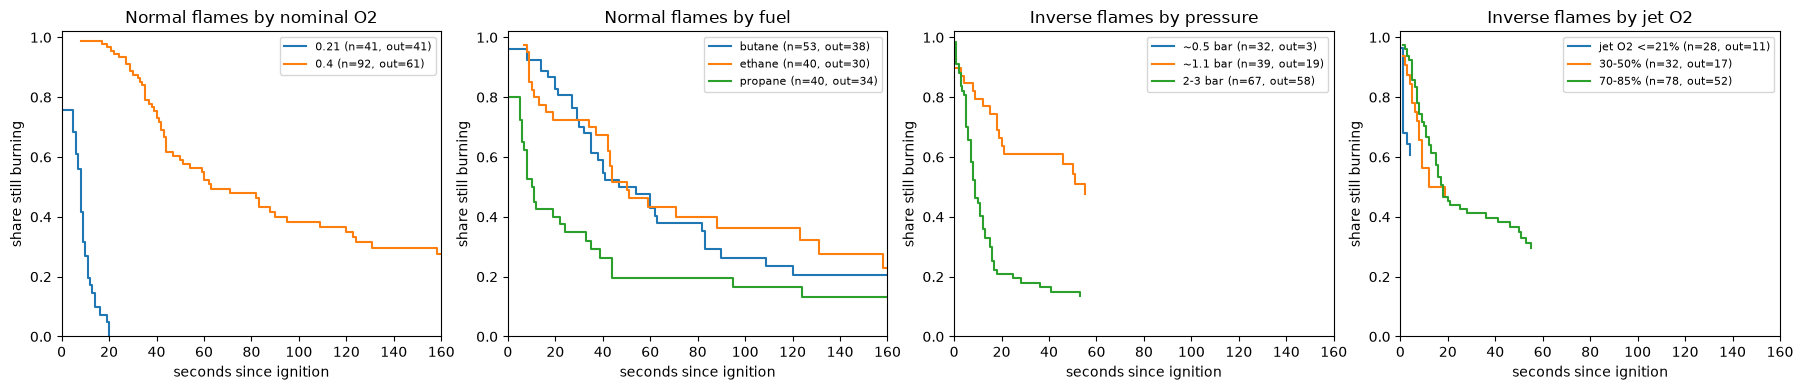

normal: median time to self-extinction among SE: 29.5 s; censored share 0.23
inverse: median time to self-extinction among SE: 8.0 s; censored share 0.42

why were flames cut (FT)?
comments
timer / operator            77
burner temperature limit    12
Name: count, dtype: int64


In [15]:
from statsmodels.duration.survfunc import SurvfuncRight
def km_plot(ax, d, by, title):
    for lvl, g in d.groupby(by):
        sf = SurvfuncRight(g['burn_time_s'].clip(lower=0.5).values, g['self_ext'].astype(int).values)
        ax.step(sf.surv_times, sf.surv_prob, where='post', label=f'{lvl} (n={len(g)}, out={int(g.self_ext.sum())})')
    ax.set_title(title); ax.set_xlabel('seconds since ignition'); ax.set_ylabel('share still burning'); ax.set_ylim(0, 1.02); ax.set_xlim(0, 160); ax.legend(fontsize=8)
nE = df[(df.flame_type == 'normal') & df['ext_model']].copy(); iE = df[(df.flame_type == 'inverse') & df['ext_model']].copy()
iE['p_level'] = pd.cut(iE['pressure_bar'], [0, 0.7, 1.5, 4], labels=['~0.5 bar', '~1.1 bar', '2-3 bar'])
nE['p_level'] = pd.cut(nE['pressure_bar'], [0, 0.7, 1.5, 4], labels=['~0.5 bar', '~1 bar', '2-3 bar'])
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
km_plot(ax[0], nE, 'o2_nominal', 'Normal flames by nominal O2')
km_plot(ax[1], nE, 'fuel', 'Normal flames by fuel')
km_plot(ax[2], iE, 'p_level', 'Inverse flames by pressure')
km_plot(ax[3], iE, pd.cut(iE['o2_frac'], [0, 0.25, 0.6, 1], labels=['jet O2 <=21%', '30-50%', '70-85%']), 'Inverse flames by jet O2')
fig.tight_layout(); fig.savefig('figures/cfig_survival.png', dpi=110); plt.show()
for name, d in [('normal', nE), ('inverse', iE)]:
    print(f'{name}: median time to self-extinction among SE: {d.loc[d.self_ext, "burn_time_s"].median()} s; censored share {1 - d.self_ext.mean():.2f}')
print('\nwhy were flames cut (FT)?'); print(df.loc[df['ext_model'] & (df['end'] == 'flow_term'), 'comments'].str.contains('limit', case=False).map({True: 'burner temperature limit', False: 'timer / operator'}).value_counts())

## 10. Shape of the effects (Cox model, grouped CV)

A Cox model says how each condition speeds up or slows down self-extinction (a "hazard ratio": > 1 = goes out sooner). We compare, out of sample (GroupKFold by chamber atmosphere), straight-line effects vs curves, using the concordance index (C: share of pairs of flames ordered correctly; 0.5 = chance).

In [16]:
from statsmodels.duration.hazard_regression import PHReg
from patsy import dmatrix, build_design_matrices
import warnings; warnings.filterwarnings('ignore')

def cindex(time, event, risk):
    n_ok = n_all = 0
    for a in range(len(time)):
        if not event[a]: continue
        later = time > time[a]
        n_all += later.sum(); n_ok += (risk[a] > risk[later]).sum() + 0.5 * (risk[a] == risk[later]).sum()
    return n_ok / n_all if n_all else np.nan

from scipy.optimize import minimize

def ridge_cox(X, time, event, alpha=1.0):
    """Cox partial likelihood (Breslow ties) with an L2 penalty, solved with L-BFGS. X standardized."""
    o = np.argsort(-time); X, time, event = X[o], time[o], event[o]   # descending time: risk set = prefix
    def f(b):
        eta = X @ b; w = np.exp(eta - eta.max())
        cw = np.cumsum(w); cwx = np.cumsum(w[:, None] * X, axis=0)
        ll = np.sum(event * (eta - eta.max() - np.log(cw)))
        grad = (event[:, None] * (X - cwx / cw[:, None])).sum(0)
        return -ll + 0.5 * alpha * b @ b, -grad + alpha * b
    return minimize(f, np.zeros(X.shape[1]), jac=True, method='L-BFGS-B').x

def fit_cox(tr, rhs, alpha=1.0):
    """Ridge-penalized Cox (inputs standardized on the training part only). Returns a function giving the log-hazard for new data."""
    X = dmatrix(rhs + ' - 1', tr, return_type='dataframe'); info = X.design_info
    X = X.loc[:, X.std() > 0]; cols = X.columns
    mu, sd = X.mean(), X.std()
    b = ridge_cox(((X - mu) / sd).values, tr['burn_time_s'].values, tr['self_ext'].astype(float).values, alpha)
    def risk(te):
        Xt = pd.DataFrame(np.asarray(build_design_matrices([info], te)[0]), columns=info.column_names)[cols]
        return ((Xt - mu) / sd).values @ b
    return risk, pd.Series(b, index=cols)

def cv_cox(d, rhs, k=5, seeds=5):
    out = []
    for seed in range(seeds):
        rng = np.random.RandomState(seed); fills = d['fill_key'].unique(); rng.shuffle(fills)
        fold = d['fill_key'].map({f: j % k for j, f in enumerate(fills)}).values
        risk = np.zeros(len(d))
        for j in range(k):
            r, _ = fit_cox(d[fold != j], rhs); risk[fold == j] = r(d[fold == j])
        out.append(cindex(d['burn_time_s'].values, d['self_ext'].values, risk))
    return np.mean(out), np.std(out)

for name, d, base, o2 in [('normal', nE, 'o2_pct + pressure_bar + jet_fuel_frac + fuel_flow_mg_s + C(fuel)', 'o2_pct'),
                          ('inverse', iE, 'o2_pct + pressure_bar + atm_fuel_pct + fuel_flow_mg_s + C(fuel)', 'o2_pct')]:
    d = d.dropna(subset=['burn_time_s']).copy(); d['burn_time_s'] = d['burn_time_s'].clip(lower=0.5)
    d['o2_pct'] = d['o2_mid'] * 100; d['atm_fuel_pct'] = d['atm_fuel_frac'] * 100
    bnd = lambda c: f'bs({c}, df=3, lower_bound={d[c].min() - 1e-6}, upper_bound={d[c].max() + 1e-6})'  # fixed range only, no outcome information
    curvy = base.replace('pressure_bar', bnd('pressure_bar')).replace('fuel_flow_mg_s', bnd('fuel_flow_mg_s'))
    print(f'--- {name}: n={len(d)}, events={int(d.self_ext.sum())}, atmospheres={d.fill_key.nunique()}')
    for label, f in [('straight lines', base), ('curves for pressure and flow', curvy), ('+ fuel x O2', base + ' + C(fuel):' + o2)]:
        print(f'   {label:32s} C = %.3f ± %.3f' % cv_cox(d, f))
    # Unpenalized fit on all data for readable hazard ratios (per 1 % O2, per bar, per mg/s)
    full = PHReg.from_formula('burn_time_s ~ ' + base, data=d, status=d['self_ext'].astype(int)).fit(disp=False)
    print(pd.DataFrame({'hazard_ratio': np.exp(full.params), 'p': full.pvalues}, index=full.model.exog_names).round(3))


--- normal: n=133, events=102, atmospheres=22


   straight lines                   C = 0.824 ± 0.004


   curves for pressure and flow     C = 0.844 ± 0.005


   + fuel x O2                      C = 0.826 ± 0.008
                    hazard_ratio      p
C(fuel)[T.ethane]          0.509  0.011
C(fuel)[T.propane]         1.026  0.930
o2_pct                     0.742  0.000
pressure_bar               2.470  0.000
jet_fuel_frac              0.844  0.710
fuel_flow_mg_s             2.428  0.000
--- inverse: n=138, events=80, atmospheres=68


   straight lines                   C = 0.712 ± 0.012


   curves for pressure and flow     C = 0.686 ± 0.006


   + fuel x O2                      C = 0.701 ± 0.012
                    hazard_ratio      p
C(fuel)[T.ethane]          0.903  0.736
C(fuel)[T.propane]         0.965  0.901
o2_pct                     1.002  0.747
pressure_bar               1.300  0.102
atm_fuel_pct               0.888  0.001
fuel_flow_mg_s             0.648  0.015


## 11. Ignition: what can be modelled

In [17]:
g = df[df['ign_model']].copy()
print(pd.crosstab(g['flame_type'], g['ignited']))
print('\ninverse non-ignitions (model set):'); print(g.loc[(g.flame_type == 'inverse') & ~g['ignited'], ['test_id', 'fuel', 'pressure_bar', 'o2_frac', 'atm_fuel_frac', 'fuel_flow_mg_s', 'comments']].to_string(index=False))
gn = g[g.flame_type == 'normal'].copy(); gn['o2_pct'] = gn['o2_mid'] * 100
print('\nnormal: non-ignitions by test day:', gn.loc[~gn['ignited'], 'test_day'].value_counts().to_dict())
print('normal: ignition share by jet fuel band and pressure:')
print(pd.crosstab(pd.cut(gn['jet_fuel_frac'], [-0.01, 0.03, 0.06, 0.2, 1]), gn['pressure_bar'].round(1), values=gn['ignited'], aggfunc='mean').round(2))
print('normal: ignition share by fuel flow band:'); print(gn.groupby(pd.cut(gn['fuel_flow_mg_s'], [-0.01, 0.3, 0.6, 1.1, 4]), observed=True)['ignited'].agg(['size', 'mean']).round(2))

ignited     False  True 
flame_type              
inverse        10    138
normal         37    133

inverse non-ignitions (model set):
test_id    fuel  pressure_bar  o2_frac  atm_fuel_frac  fuel_flow_mg_s         comments
21196A1  ethane       1.10000     0.21       0.298100            1.50 Failed to ignite
21196H1  ethane       1.10330     0.12       0.291765            1.50      Not ignited
21202A1  ethane       2.20660     0.85       0.060000            0.25      No ignition
21222F2 propane       3.30990     0.21       0.079622            0.50      No ignition
21235F2 propane       1.10330     0.21       0.199695            2.50                 
21265F3  butane       3.30990     0.21       0.057091            1.00      No ignition
21265F4  butane       3.30990     0.21       0.057091            1.00      No ignition
21277J1  butane       0.55165     0.21       0.359430            1.50      No ignition
21277K1  butane       0.55165     0.30       0.359430            1.50      No ign

In [18]:
# Normal-flame ignition, out-of-sample (GroupKFold by chamber atmosphere), regularized logistic
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder, SplineTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, log_loss
gn['log_jet_fuel'] = np.log10(gn['jet_fuel_frac'].clip(lower=0.005))
y = gn['ignited'].astype(int).values
def run(cols, spl=False, seeds=5):
    res = []
    for s in range(seeds):
        fills = gn['fill_key'].unique(); np.random.RandomState(s).shuffle(fills)
        fold = gn['fill_key'].map({f: j % 5 for j, f in enumerate(fills)}).values; oof = np.zeros(len(y))
        for j in range(5):
            num = [c for c in cols if c != 'fuel']
            pre = ColumnTransformer([('n', SplineTransformer(n_knots=4) if spl else StandardScaler(), num)] + ([('f', OneHotEncoder(handle_unknown='ignore'), ['fuel'])] if 'fuel' in cols else []))
            tr = fold != j
            if len(set(y[tr])) < 2: oof[~tr] = y[tr].mean(); continue
            oof[~tr] = make_pipeline(pre, LogisticRegression(C=1.0, max_iter=5000)).fit(gn[tr], y[tr]).predict_proba(gn[~tr])[:, 1]
        res.append((roc_auc_score(y, oof), log_loss(y, np.clip(oof, 1e-4, 1 - 1e-4))))
    return np.round(np.mean(res, axis=0), 3)
for label, cols, spl in [('jet fuel fraction only', ['log_jet_fuel'], False),
                         ('+ O2, pressure, flow, fuel', ['log_jet_fuel', 'o2_pct', 'pressure_bar', 'fuel_flow_mg_s', 'fuel'], False),
                         ('same with curves', ['log_jet_fuel', 'o2_pct', 'pressure_bar', 'fuel_flow_mg_s'], True)]:
    print(f'{label:30s} AUC, log loss =', run(cols, spl))
print('base rate log loss:', round(log_loss(y, np.full(len(y), y.mean())), 3))

jet fuel fraction only         AUC, log loss = [0.719 0.458]


+ O2, pressure, flow, fuel     AUC, log loss = [0.633 0.595]


same with curves               AUC, log loss = [0.82  0.452]
base rate log loss: 0.524


## 12. Inputs vs results

In [19]:
roles = {
 'inputs (set before ignition)': ['flame_type (separate models)', 'fuel', 'pressure_bar', 'o2_mid (normal: avg before/after) / o2_frac (inverse jet)', 'jet_fuel_frac (normal)', 'atm_fuel_frac (inverse)', 'fuel_flow_mg_s'],
 'targets': ['ignited (normal flames)', 'burn_time_s + self_ext (event) / flow_term (censored)'],
 'results / observed during the test (never inputs)': ['peak_burner_c', 'color', 'cool_flame_raw', 'comments'],
 'computed from the inputs (redundant, not used)': ['tad_k', 'zst', 'o2_flow_mg_s (inverse, = fuel flow x ~3.65)'],
 'bookkeeping / diagnostics (never inputs)': ['test_id', 'test_day', 'day_no', 'tfp', 'fill_key (CV only)', 'group_id', 'flags'],
}
for k, v in roles.items(): print(f'{k}:\n   ' + ', '.join(v))

inputs (set before ignition):
   flame_type (separate models), fuel, pressure_bar, o2_mid (normal: avg before/after) / o2_frac (inverse jet), jet_fuel_frac (normal), atm_fuel_frac (inverse), fuel_flow_mg_s
targets:
   ignited (normal flames), burn_time_s + self_ext (event) / flow_term (censored)
results / observed during the test (never inputs):
   peak_burner_c, color, cool_flame_raw, comments
computed from the inputs (redundant, not used):
   tad_k, zst, o2_flow_mg_s (inverse, = fuel flow x ~3.65)
bookkeeping / diagnostics (never inputs):
   test_id, test_day, day_no, tfp, fill_key (CV only), group_id, flags


### 12.1 Conclusions and decisions for §9–12 (Claude, autonomous mode; DD-029 to DD-031)

**Self-extinction (survival, ridge Cox, GroupKFold by chamber atmosphere):**
- **Normal flames** (133 flames, 102 went out, 22 atmospheres): C = 0.82 out of sample. Each extra point of O₂ makes self-extinction ~26 % less likely per unit time (hazard ratio 0.74 per 1 % O₂); higher pressure and bigger flames (more fuel flow) make it go out sooner (×2.5 per bar, ×2.4 per mg/s) — bigger, brighter flames lose more heat by radiation. Ethane goes out more slowly than butane. The jet fuel fraction does not matter once the flame is lit. Curves for pressure and flow gain a little (C 0.84); with 5 pressure levels and 22 atmospheres this is not enough to justify them → **straight lines**, curves re-checked at modelling time.
- **Inverse flames** (138 flames, 80 went out, 68 atmospheres): C = 0.71. Jet O₂ barely matters; more fuel in the atmosphere and bigger flows keep the flame alive longer; pressure pushes towards extinction but is tied to the fuel fraction by design (ρ = −0.80). Curves do not help → **straight lines**.
- Limitation: 12 flames were cut because the burner hit its temperature limit; that censoring is not random (strong flames). It is reported, not corrected.

**Ignition (normal flames only):** 37 real non-ignitions, 27 of them on two days with very diluted jets. Adding O₂, pressure, flow and fuel does not improve on the jet fuel fraction alone out of sample (AUC 0.63 vs 0.72; curves 0.82 but same log loss 0.45). → **one-input logistic on the (log) jet fuel fraction**: it gives the "too diluted to light" threshold, which is what the data support. Inverse-flame ignition (10 failures) is evidence only.

**Inputs:** only the set conditions (§12 table). O₂ for normal flames = average before/after (DD-029). Evaluation groups = chamber atmosphere (DD-030).

## 13. CFI-G EDA — closing summary

| Topic | Result | Decision |
|---|---|---|
| Source | 179 normal + 154 inverse tests; NASA final report read; 861 empty rows dropped | DD-028 |
| Labels | 2 contradictions solved with the same row's evidence; `flash` = lit and out at once | DD-026, DD-028 |
| "No ignition" not about gas | 9 low-energy trials, 5 hardware failures, 1 wrong conditions | DD-027: kept, out of the ignition model |
| `FT` | Gas cut with the flame alive → censored | Survival model (LC) |
| Missing | Only outputs, all explained | No imputation |
| Drift | Normal O₂ falls up to 8 points in a day | DD-029: O₂ = avg before/after |
| Dependencies | Flames share chamber atmospheres; exact combos unique | DD-030: GroupKFold by atmosphere |
| Overlap | Inverse O₂ flow = fuel flow × 3.65; inverse pressure ~ fuel fraction | Use fuel flow only; read pressure with care |
| Models | Cox per flame type (straight lines); ignition: jet fuel fraction | DD-031 |
| Evidence only | Cool flames (15), inverse ignition, peak burner T, colour | — |

In [20]:
import os
os.makedirs('../data/processed', exist_ok=True)
keep = ['test_id', 'flame_type', 'test_day', 'day_no', 'fuel', 'fuel_bottle_frac', 'pressure_bar', 'o2_frac', 'o2_frac_after', 'o2_mid', 'o2_nominal',
        'jet_fuel_frac', 'atm_fuel_frac', 'fuel_flow_mg_s', 'o2_flow_mg_s', 'tad_k', 'zst', 'tfp', 'hot_ignition_raw', 'ignition', 'ignited',
        'end_raw', 'end', 'self_ext', 'burn_time_s', 'peak_burner_c', 'cool_flame_raw', 'color', 'comments',
        'corrected_label', 'low_energy_ignition', 'hardware_issue', 'conditions_wrong', 'ign_model', 'ext_model', 'fill_key']
out = df[keep].copy()
out['ign_model'] = out['ign_model'] & (out['flame_type'] == 'normal')   # DD-031: inverse ignition is evidence only
out['source'] = 'PSI-159 CSV (Normal/Inverse Flames)'
out.to_parquet('../data/processed/cfig_tests.parquet', index=False)
print(out.shape, '-> data/processed/cfig_tests.parquet')
print('ignition model (normal):', int(out['ign_model'].sum()), '| self-extinction normal:', int((out['ext_model'] & (out.flame_type == 'normal')).sum()), '| inverse:', int((out['ext_model'] & (out.flame_type == 'inverse')).sum()))

(333, 37) -> data/processed/cfig_tests.parquet
ignition model (normal): 170 | self-extinction normal: 133 | inverse: 138
